# 07 - Random Forest on full HDFS

A supervised Random Forest on the block count vectors, with three ways of handling the class imbalance.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models.supervised import evaluate_rf, shap_top_events, top_importances, train_rf
from src.models.unsupervised import time_split

pd.set_option("display.max_colwidth", 100)
DOCS = ROOT / "docs"

counts = pd.read_parquet(ROOT / "data" / "processed" / "hdfs_counts.parquet")
templates = pd.read_csv(ROOT / "data" / "processed" / "hdfs_templates.csv").set_index("EventId")["template"]
event_cols = [c for c in counts.columns if c.startswith("E")]

## Train / test split

Same split as notebook 06: first 70% of blocks by first appearance for training, last 30% for testing. This time the model trains on both classes.

In [2]:
train, test = time_split(counts, train_frac=0.7)
X_train, y_train = train[event_cols], train["Label"]
X_test, y_test = test[event_cols], test["Label"]

pd.DataFrame({
    "blocks": [len(train), len(test)],
    "anomalous blocks": [y_train.sum(), y_test.sum()],
}, index=["train (first 70%)", "test (last 30%)"])

,blocks,anomalous blocks
train (first 70%),402542,13115
test (last 30%),172519,3723


## Train and evaluate

100 trees each: (a) no imbalance handling, (b) `class_weight='balanced'`, (c) SMOTE on the training set only. Training time includes SMOTE.

In [3]:
methods = {"none": "No imbalance handling", "balanced": "class_weight='balanced'", "smote": "SMOTE"}
models, rows = {}, []
for key, label in methods.items():
    models[key], fit_s = train_rf(X_train, y_train, method=key)
    rows.append({"method": label, **evaluate_rf(models[key], X_test, y_test), "train_seconds": fit_s})

results = pd.DataFrame(rows)[["method", "precision", "recall", "f1", "false_alarm_rate", "roc_auc", "train_seconds"]]
DOCS.mkdir(exist_ok=True)
results.round(4).to_csv(DOCS / "hdfs_rf_results.csv", index=False)
results.style.format({c: "{:.4f}" for c in ["precision", "recall", "f1", "false_alarm_rate", "roc_auc"]} | {"train_seconds": "{:.1f}"}).hide(axis="index")

method,precision,recall,f1,false_alarm_rate,roc_auc,train_seconds
No imbalance handling,1.0000,0.9984,0.9992,0.0000,1.0000,3.8
class_weight='balanced',1.0000,0.9984,0.9992,0.0000,1.0000,4.5
SMOTE,0.9655,0.9989,0.9819,0.0008,1.0000,10.2


## Feature importance

Top 10 impurity-based importances for the method with the best F1.

In [4]:
best = list(methods)[results["f1"].idxmax()]
best_model = models[best]
print(f"Best method: {methods[best]}")

importances = top_importances(best_model, event_cols, templates)
importances.index += 1
importances

Best method: No imbalance handling


,event,importance,template
1,E33,0.252697,Unexpected error trying to delete block <BLK>. BlockInfo not found in volumeMap.
2,E5,0.170885,BLOCK* NameSystem.addStoredBlock: blockMap updated: <IP> is added to <BLK> size <NUM>
3,E1,0.110105,Receiving block <BLK> src: /<IP> dest: /<IP>
4,E4,0.081722,Received block <BLK> of size <NUM> from /<IP>
5,E17,0.069036,Deleting block <BLK> file <*>
6,E21,0.053232,BLOCK* NameSystem.addStoredBlock: Redundant addStoredBlock request received for <BLK> on <IP> si...
7,E34,0.048354,BLOCK* NameSystem.addStoredBlock: addStoredBlock request received for <BLK> on <IP> size <NUM> B...
8,E3,0.045867,PacketResponder <NUM> for block <BLK> <*>
9,E16,0.028467,writeBlock <BLK> received exception java.io.IOException: Could not read from stream
10,E11,0.026728,BLOCK* ask <IP> to replicate <BLK> to datanode(s) <IP>


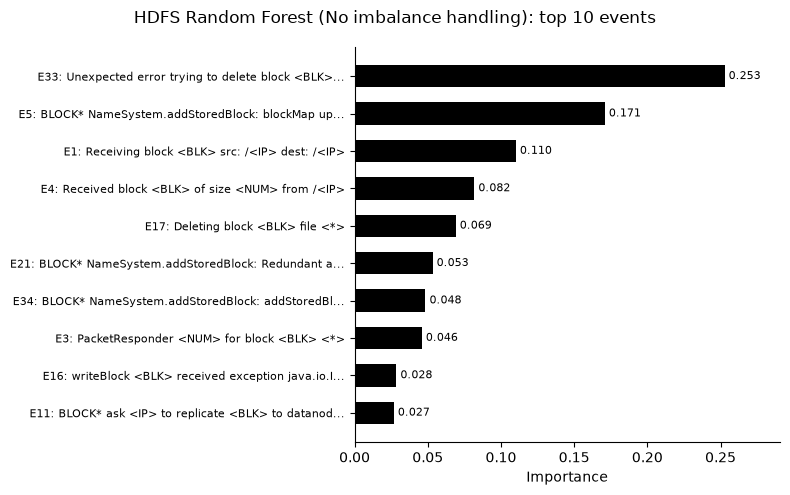

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
labels = [f"{e}: {t[:45]}{'...' if len(t) > 45 else ''}" for e, t in zip(importances["event"], importances["template"])]
ax.barh(labels[::-1], importances["importance"][::-1], color="black", height=0.6)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3, fontsize=8)

ax.set_xlabel("Importance")
fig.suptitle(f"HDFS Random Forest ({methods[best]}): top 10 events")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlim(0, importances["importance"].max() * 1.15)

fig.tight_layout()
fig.savefig(DOCS / "hdfs_rf_importance.png", dpi=150, facecolor="white")
plt.show()

## SHAP explanation for one detected anomaly

We take the correctly detected anomalous block with the highest anomaly probability. A count of 0 can also be evidence, since the model learns which events are missing.

In [6]:
proba = best_model.predict_proba(X_test)[:, 1]
detected = (y_test.to_numpy() == 1) & (best_model.predict(X_test) == 1)
pos = proba[detected].argmax()
x = X_test[detected].iloc[[pos]]
block_id = test.loc[x.index[0], "BlockId"]

top3 = shap_top_events(best_model, x, event_cols, templates)
print(f"Block {block_id}: {proba[detected][pos]:.0%} anomaly probability. Top 3 events:")
for row in top3.itertuples():
    print(f'- "{row.template}" ({row.event}), count {row.count}: {row.shap:+.0%}')

Block blk_6583756684942329540: 100% anomaly probability. Top 3 events:
- "Unexpected error trying to delete block <BLK>. BlockInfo not found in volumeMap." (E33), count 1: +94%
- "Deleting block <BLK> file <*>" (E17), count 3: +1%
- "<IP>:Got exception while serving <BLK> to /<IP>:" (E35), count 0: +1%
